### 加载数据

In [1]:
import polars as pl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from skfolio import Population,MultiPeriodPortfolio
from skfolio import RiskMeasure, PerfMeasure, RatioMeasure
from skfolio.datasets import load_sp500_dataset
from skfolio.preprocessing import prices_to_returns
from ml4t.data.providers.qmt_provider import QmtProvider
from sklearn import set_config
from log_result import init_logger, log_result, log_print
from synthetic_returns import estimate_marginal_stats, synthesize_returns
set_config(transform_output="pandas")
init_logger("CSCV_OOS")      # 只调用一次, 绑定文件名
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False   # 关键: 负号才不会变方块

[log] 已绑定: D:\machine-learning-for-trading\case_studies\lazy_trading\logs\CSCV_OOS.log


In [68]:
# 加载数据
prices = pl.read_parquet("hs_funds_prices.parquet").to_pandas()
prices = prices.set_index('timestamp')
prices = prices.ffill()
#prices = prices[prices.index.year > 2010]
prices = prices[prices.index.year < 2017]
all_symbols = prices.columns
log_print(f"资产池: {len(all_symbols)} 只 | {len(prices)} 天 | {prices.index[0].date()} ~ {prices.index[-1].date()}",section="资产池", echo=True)

# 市场基准（从资产池中取出）
bench_symbols = ["510880.SH","510300.SH"]
benchs = [prices[bench_symbol] for bench_symbol in bench_symbols]
#prices = prices.drop(columns=bench_symbols)

# 双口径收益率: X=绝对收益, X_net=超额收益(减基准), 筛选与训练统一用X_net
X = prices_to_returns(prices, drop_inceptions_nan=False)
bench_rets = [prices_to_returns(bench.to_frame("bench"), drop_inceptions_nan=False)["bench"] for bench in benchs]
X_net = X.sub(bench_rets[1], axis=0)

# Inf 检查（两口径分别报告）
for label, df in [("X", X), ("X_net", X_net)]:
    inf = df.columns[np.isinf(df).any(axis=0)]
    print(f"{label} Inf列 {len(inf)}" + (f" -> {inf.tolist()}" if len(inf) else ""))

# 异常收益检查: 以超额口径判定, 同步剔除, 保证两口径列集一致
bad = X_net.columns[(X_net.abs() > 0.25).any()]
X = X.drop(columns=bad)
X_net = X_net.drop(columns=bad)
msg = f"异常剔除(±25%): {len(bad)} 列 -> {bad.tolist()}" if len(bad) else "异常剔除(±25%): 0 列"
print(msg)
print(f"清洗后: {X.shape[0]} 天 x {X.shape[1]} 资产 | 列集一致: {list(X.columns) == list(X_net.columns)}")

资产池: 2141 只 | 1700 天 | 2010-01-04 ~ 2016-12-30
X Inf列 0
X_net Inf列 0
异常剔除(±25%): 0 列
清洗后: 1699 天 x 305 资产 | 列集一致: True


In [3]:
#stats  = estimate_marginal_stats(X)                        # ① 逐标的统计属性 + 拟合参数表
#X_fake = synthesize_returns(X, random_state=42)            # ② 默认 student_t + 保留截面相关
#X_fake, report = synthesize_returns(X, random_state=42, return_report=True)
X_ctrl = synthesize_returns(X, distribution="gaussian")    # 高斯对照项
X_fake = synthesize_returns(X, random_state=42)

硬截断告警：2 列截断比例超过阈值（最高 161125.SZ: 截断 25.00% / 阈值 46.15% / 样本 12）
硬截断告警：2 列截断比例超过阈值（最高 161127.SZ: 截断 33.33% / 阈值 150.00% / 样本 3）


In [ ]:
from cpcv_search_base import build_pipeline_src
from cpcv_analysis import plot_oos_vs_bench
from sl_simulation import load_sl_config, simulate_sl, summarize_sl, simulate_fixed, simulate_wf

### Fixed Simulate

In [ ]:
18-26{'nondomin__min_n_assets': 85, 'nondomin__threshold': -0.4, 'correlate__threshold': 0.1, 'extremes__k': 0.6, 'nondomin__fitness_measures': 'mean-variance-maxdd-kurt', 'train_size': 252}
16-26{'nondomin__min_n_assets': 95, 'nondomin__threshold': -0.5, 'correlate__threshold': 0.1, 'extremes__k': 0.8, 'nondomin__fitness_measures': 'mean-variance-maxdd-kurt', 'train_size': 504}
16-24{'nondomin__min_n_assets': 55, 'nondomin__threshold': -0.3, 'correlate__threshold': 0.1, 'extremes__k': 0.7, 'nondomin__fitness_measures': 'mean-variance-maxdd-kurt', 'train_size': 252}
17-25{'nondomin__min_n_assets': 45, 'nondomin__threshold': -0.5, 'correlate__threshold': 0.1, 'extremes__k': 0.6, 'nondomin__fitness_measures': 'mean-variance-maxdd-kurt', 'train_size': 252}
18-26-126{'nondomin__min_n_assets': 85, 'nondomin__threshold': -0.4, 'correlate__threshold': 0.1, 'extremes__k': 0.8, 'nondomin__fitness_measures': 'mean-variance-maxdd-kurt', 'train_size': 504}
17-21  852  {'nondomin__min_n_assets': 75, 'nondomin__threshold': -0.5, 'correlate__threshold': 0.2, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'mean-variance-maxdd-kurt', 'train_size': 252}
19-23  1999  {'nondomin__min_n_assets': 45, 'nondomin__threshold': -0.5, 'correlate__threshold': 0.1, 'extremes__k': 0.5, 'nondomin__fitness_measures': 'mean-variance-maxdd-kurt', 'train_size': 252}


In [89]:
best_param1 = {'nondomin__min_n_assets': 85, 'nondomin__threshold': -0.4, 'correlate__threshold': 0.1, 'extremes__k': 0.6, 'nondomin__fitness_measures': 'mean-variance-maxdd-kurt', 'train_size': 252}
best_param2 = {'nondomin__min_n_assets': 95, 'nondomin__threshold': -0.5, 'correlate__threshold': 0.1, 'extremes__k': 0.8, 'nondomin__fitness_measures': 'mean-variance-maxdd-kurt', 'train_size': 504}
best_param3 = {'nondomin__min_n_assets': 55, 'nondomin__threshold': -0.3, 'correlate__threshold': 0.1, 'extremes__k': 0.7, 'nondomin__fitness_measures': 'mean-variance-maxdd-kurt', 'train_size': 252}
best_param4 = {'nondomin__min_n_assets': 45, 'nondomin__threshold': -0.5, 'correlate__threshold': 0.1, 'extremes__k': 0.6, 'nondomin__fitness_measures': 'mean-variance-maxdd-kurt', 'train_size': 252}
best_param5 = {'nondomin__min_n_assets': 75, 'nondomin__threshold': -0.5, 'correlate__threshold': 0.2, 'extremes__k': 0.9, 'nondomin__fitness_measures': 'mean-variance-maxdd-kurt', 'train_size': 252}
best_param6 = {'nondomin__min_n_assets': 45, 'nondomin__threshold': -0.5, 'correlate__threshold': 0.1, 'extremes__k': 0.5, 'nondomin__fitness_measures': 'mean-variance-maxdd-kurt', 'train_size': 252}



In [ ]:
res1 = simulate_wf(X, params=best_param1, test_size=252)
res2 = simulate_wf(X, params=best_param2, test_size=252)
res3 = simulate_wf(X, params=best_param3, test_size=252)
res4 = simulate_wf(X, params=best_param4, test_size=252)


Fold 0: 2011-01-19 -> 2012-02-06 (252d, expired) | wf | ASR=-0.962 | 累计=-4.50%
Fold 1: 2012-02-07 -> 2013-02-19 (252d, expired) | wf | ASR=0.226 | 累计=2.44%
Fold 2: 2013-02-20 -> 2014-03-07 (252d, expired) | wf | ASR=0.747 | 累计=14.57%
Fold 3: 2014-03-10 -> 2015-03-19 (252d, expired) | wf | ASR=1.524 | 累计=44.26%
Fold 4: 2015-03-20 -> 2016-03-29 (252d, expired) | wf | ASR=0.609 | 累计=10.29%
Fold 5: 2016-03-30 -> 2016-12-30 (187d, end_of_data) | wf | ASR=0.363 | 累计=0.99%
Fold 0: 2012-02-07 -> 2013-02-19 (252d, expired) | wf | ASR=0.938 | 累计=15.30%
Fold 1: 2013-02-20 -> 2014-03-07 (252d, expired) | wf | ASR=-0.192 | 累计=-7.45%
Fold 2: 2014-03-10 -> 2015-03-19 (252d, expired) | wf | ASR=2.527 | 累计=55.39%
Fold 3: 2015-03-20 -> 2016-03-29 (252d, expired) | wf | ASR=0.462 | 累计=9.48%
Fold 4: 2016-03-30 -> 2016-12-30 (187d, end_of_data) | wf | ASR=0.970 | 累计=5.46%
Fold 0: 2011-01-19 -> 2012-02-06 (252d, expired) | wf | ASR=-0.962 | 累计=-4.50%
Fold 1: 2012-02-07 -> 2013-02-19 (252d, expired) | wf | A

In [87]:

res5 = simulate_wf(X, params=best_param5, test_size=252)

Fold 0: 2011-01-19 -> 2012-02-06 (252d, expired) | wf | ASR=-1.306 | 累计=-10.23%
Fold 1: 2012-02-07 -> 2013-02-19 (252d, expired) | wf | ASR=1.216 | 累计=19.22%
Fold 2: 2013-02-20 -> 2014-03-07 (252d, expired) | wf | ASR=0.189 | 累计=1.60%
Fold 3: 2014-03-10 -> 2015-03-19 (252d, expired) | wf | ASR=2.896 | 累计=33.68%
Fold 4: 2015-03-20 -> 2016-03-29 (252d, expired) | wf | ASR=0.447 | 累计=8.53%
Fold 5: 2016-03-30 -> 2016-12-30 (187d, end_of_data) | wf | ASR=0.589 | 累计=1.70%


In [90]:

res6 = simulate_wf(X, params=best_param6, test_size=252)

Fold 0: 2011-01-19 -> 2012-02-06 (252d, expired) | wf | ASR=-0.887 | 累计=-6.10%
Fold 1: 2012-02-07 -> 2013-02-19 (252d, expired) | wf | ASR=0.193 | 累计=1.87%
Fold 2: 2013-02-20 -> 2014-03-07 (252d, expired) | wf | ASR=0.793 | 累计=16.31%
Fold 3: 2014-03-10 -> 2015-03-19 (252d, expired) | wf | ASR=1.919 | 累计=54.14%
Fold 4: 2015-03-20 -> 2016-03-29 (252d, expired) | wf | ASR=0.682 | 累计=17.47%
Fold 5: 2016-03-30 -> 2016-12-30 (187d, end_of_data) | wf | ASR=1.405 | 累计=5.26%


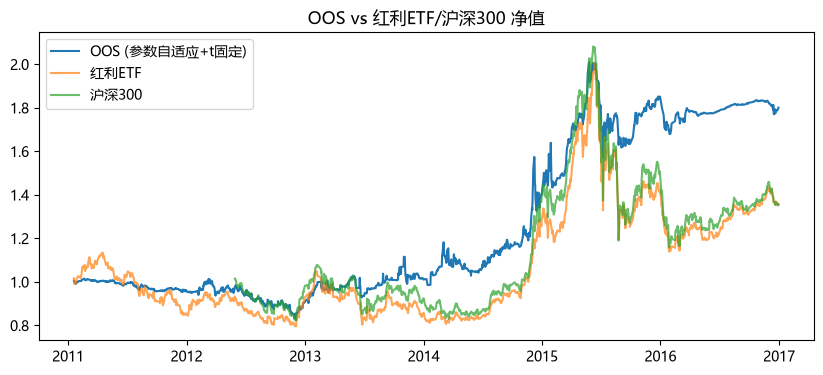

In [70]:
plot_oos_vs_bench(res1['mpt'], bench_rets, bench_labels=['红利ETF','沪深300'])

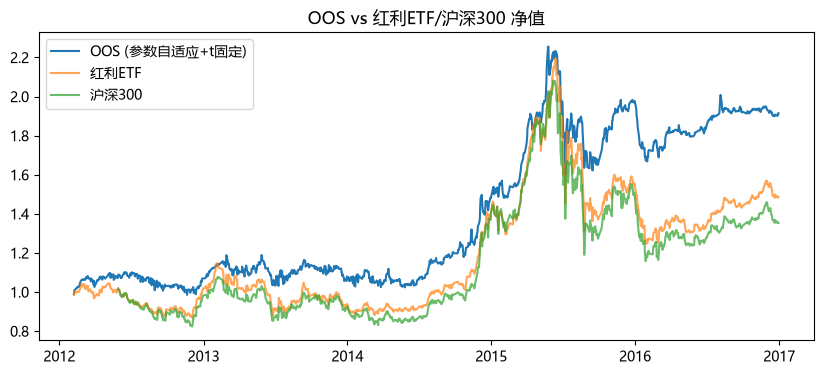

In [71]:
plot_oos_vs_bench(res2['mpt'], bench_rets, bench_labels=['红利ETF','沪深300'])

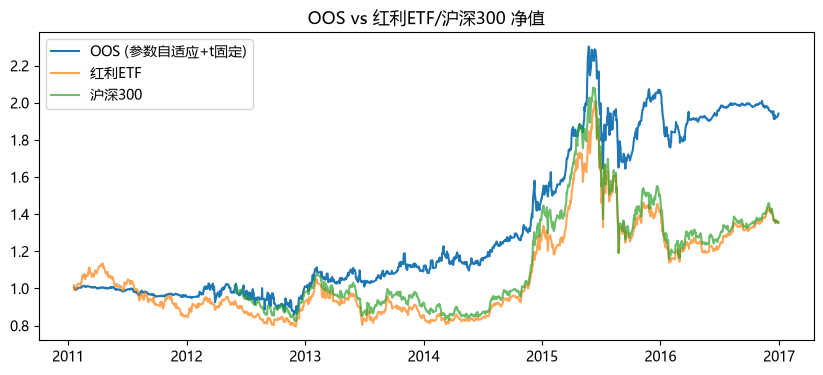

In [72]:
plot_oos_vs_bench(res3['mpt'], bench_rets, bench_labels=['红利ETF','沪深300'])

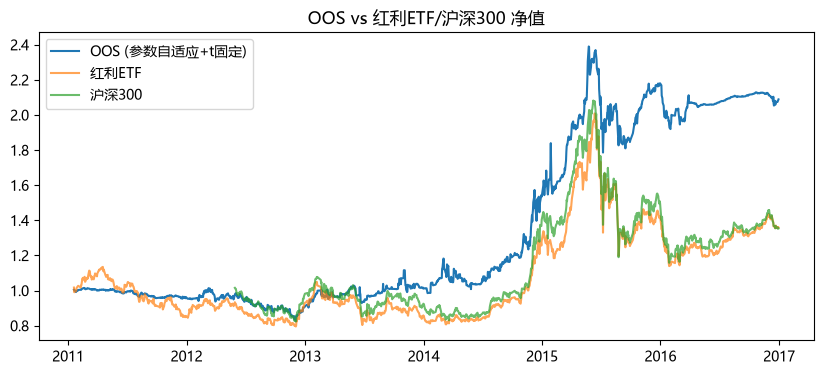

In [73]:
plot_oos_vs_bench(res4['mpt'], bench_rets, bench_labels=['红利ETF','沪深300'])

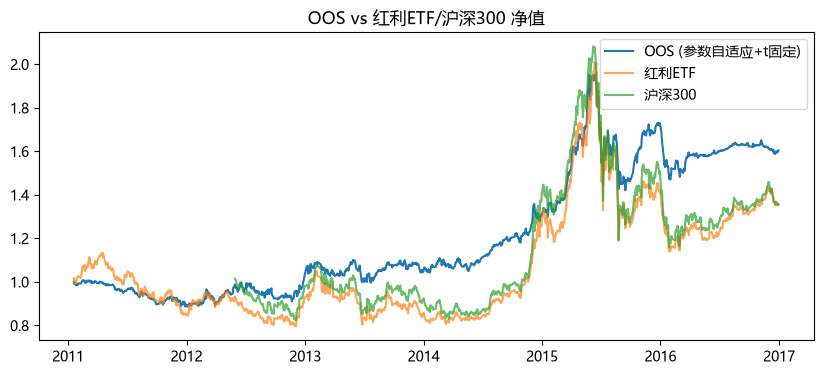

In [88]:
plot_oos_vs_bench(res5['mpt'], bench_rets, bench_labels=['红利ETF','沪深300'])

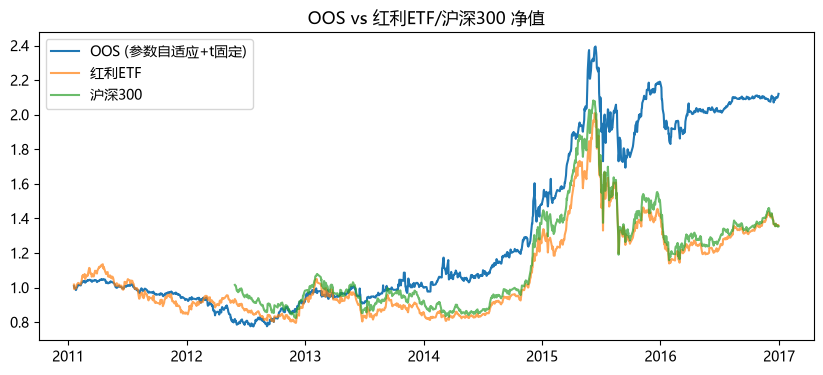

In [91]:
plot_oos_vs_bench(res6['mpt'], bench_rets, bench_labels=['红利ETF','沪深300'])

In [20]:
from skfolio import Population

In [92]:
res1['mpt'].name = '18-26'
res2['mpt'].name = '16-26'
res3['mpt'].name = '16-24'
res4['mpt'].name = '17-25'
res5['mpt'].name = '17-21'
res6['mpt'].name = '19-23'

In [93]:
pop = Population([res1['mpt'], res2['mpt'], res3['mpt'], res4['mpt'], res5['mpt'], res6['mpt']])

In [94]:
pop.plot_cumulative_returns()

In [95]:
pop.plot_drawdowns()

In [96]:
pop.plot_returns_distribution()

In [97]:
pop.summary()

,18-26,16-26,16-24,17-25,17-21,19-23
Mean,0.047%,0.063%,0.055%,0.059%,0.037%,0.060%
Annualized Mean,11.84%,15.87%,13.77%,14.78%,9.32%,15.15%
Variance,0.013%,0.017%,0.018%,0.015%,0.0086%,0.016%
Annualized Variance,3.18%,4.33%,4.42%,3.89%,2.17%,4.11%
Semi-Variance,0.0061%,0.0091%,0.0088%,0.0075%,0.0045%,0.0084%
Annualized Semi-Variance,1.54%,2.31%,2.23%,1.89%,1.14%,2.11%
Standard Deviation,1.12%,1.31%,1.32%,1.24%,0.93%,1.28%
Annualized Standard Deviation,17.84%,20.81%,21.01%,19.72%,14.72%,20.28%
Semi-Deviation,0.78%,0.96%,0.94%,0.86%,0.67%,0.91%
Annualized Semi-Deviation,12.42%,15.18%,14.93%,13.73%,10.66%,14.52%


In [67]:
pop.summary()

,18-26,16-26,16-24,17-25
Mean,0.034%,0.041%,0.038%,0.034%
Annualized Mean,8.64%,10.45%,9.62%,8.48%
Variance,0.0067%,0.0076%,0.0074%,0.0069%
Annualized Variance,1.69%,1.91%,1.87%,1.75%
Semi-Variance,0.0034%,0.0040%,0.0037%,0.0035%
Annualized Semi-Variance,0.85%,1.00%,0.94%,0.89%
Standard Deviation,0.82%,0.87%,0.86%,0.83%
Annualized Standard Deviation,13.00%,13.83%,13.69%,13.23%
Semi-Deviation,0.58%,0.63%,0.61%,0.60%
Annualized Semi-Deviation,9.21%,10.00%,9.71%,9.46%
